# Exercise 6 — Bring your own target

*Covers notebooks all. Difficulty: open*

Your science, LFAST, and Jupyter AI as a pair programmer.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, Sky, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude, plot_vs_n_telescopes, equivalent_diameter_axis

plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 10, "legend.fontsize": 8})

This exercise has no solution key beyond a worked example. Work with Jupyter AI as a pair
programmer: you supply the astronomy, it supplies the code, you check the numbers.

### 6.1 — Pick a target

A star, a transient, a planet host, a young star, an AGN. Write down: its magnitude and the band it
is quoted in, its spectral shape (temperature, power-law slope, or a spectrum file), the feature or
window you care about, the SNR you need there and why, and the instrument (Bench mode, or CSHELL
with one setting).

### 6.2 — Describe it to the agent

A prompt that works: *"I want to observe `<target>` (`<band>` = `<mag>`, `<Teff>` K) with LFAST
using lfast_etc. Build LFASTETC with the `<preset>` preset and 20 telescopes, a Source.blackbody
normalised in `<band>`, and report the median exposure time for SNR `<snr>` per resel over
`<lo>` to `<hi>` nm, the number of reads needed to avoid saturation, and which noise term dominates
there. Then show how the time changes with 100 and 200 telescopes."*

Check what it does against notebooks 02 and 03: did it restrict CSHELL to one setting? Did it
check `saturated`? Did it quote SNR per resel or per pixel?

In [2]:
# Worked example: a Ca II triplet velocity for a V = 17 K giant (RGB tip at ~80 kpc) in the red
# bench_740vph_o1 mode (772-987 nm, R ~ 3600), SNR 30 per resel over 845-870 nm.
ins = Instrument.from_preset("bench_740vph_o1")
print(ins.description, f"{ins.wavelength_min_nm:.0f}-{ins.wavelength_max_nm:.0f} nm, R={ins.resolving_power:.0f}")
giant = Source.blackbody(4500, 17, "V")
for n in (20, 100, 200):
    e = LFASTETC(ins, n_telescopes=n)
    r = e.exptime(giant, snr=30)
    win = (r.wavelength >= 845) & (r.wavelength <= 870)
    print(f"N={n:3d}: median exposure for SNR 30 over 845-870 nm = {np.nanmedian(r.exptime[win]) / 60:6.1f} min")

WIYN Bench, 740 VPH, order 1, 772-987 nm, R~3600 772-987 nm, R=3599
N= 20: median exposure for SNR 30 over 845-870 nm =   10.9 min
N=100: median exposure for SNR 30 over 845-870 nm =    2.6 min
N=200: median exposure for SNR 30 over 845-870 nm =    1.5 min


### 6.3 — One plot, one number

Produce the one plot that answers your question (exposure time versus magnitude, the noise budget,
a sensitivity map, the array-size sweep) and the one number you would put in a proposal.

30 min, 20 telescopes: median SNR/resel over the Ca II triplet = 50.6


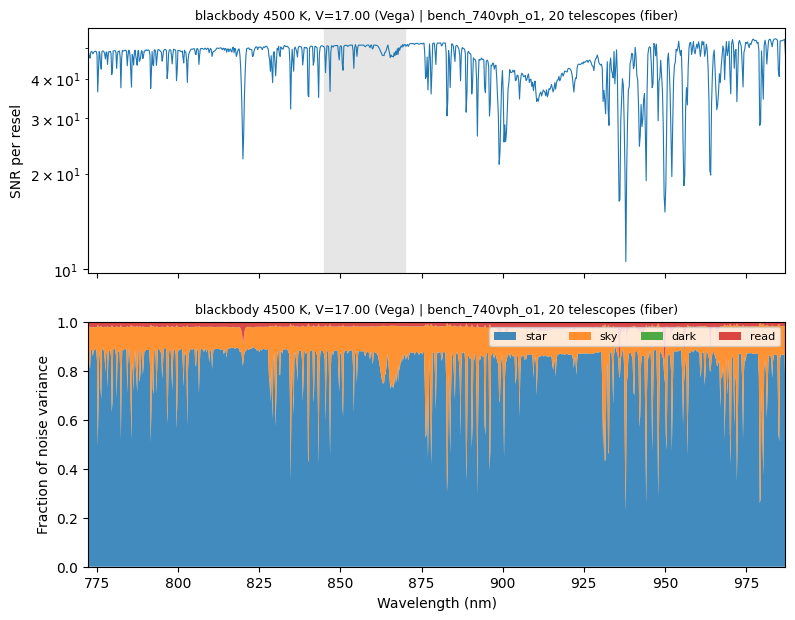

In [3]:
e = LFASTETC(ins, n_telescopes=20)
r = e.snr(giant, exptime=1800)
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
r.plot(ax=axes[0]); axes[0].axvspan(845, 870, color="0.9", zorder=0)
r.plot_noise_budget(ax=axes[1]); axes[0].set_xlabel("")
print(f"30 min, 20 telescopes: median SNR/resel over the Ca II triplet = {np.nanmedian(r.snr[(r.wavelength >= 845) & (r.wavelength <= 870)]):.1f}")

### 6.4 — What was wrong

Ask the agent to list every assumption it made that you did not state (blackbody instead of a real
spectrum, grey sky, no overheads, no slit or fiber losses beyond the model, flat QE, the placeholder
Bench efficiencies). Which would change the answer by more than a factor of two?

> 🤖 **Ask Jupyter AI:** *List every assumption you made in 6.2 that I did not state, and for each one estimate how much the exposure time would change if it were wrong.*

***
## Share-back and feedback

Bring back **one plot and one number** to the share-back board, and the observing decision you draw
from them.

> 🤖 **Ask Jupyter AI:** *Draft a GitHub issue for schmidt-observatories/lfast-etc describing one thing I
> found missing, confusing or wrong in this exercise, with a minimal code example.*